Saving images.jfif to images.jfif


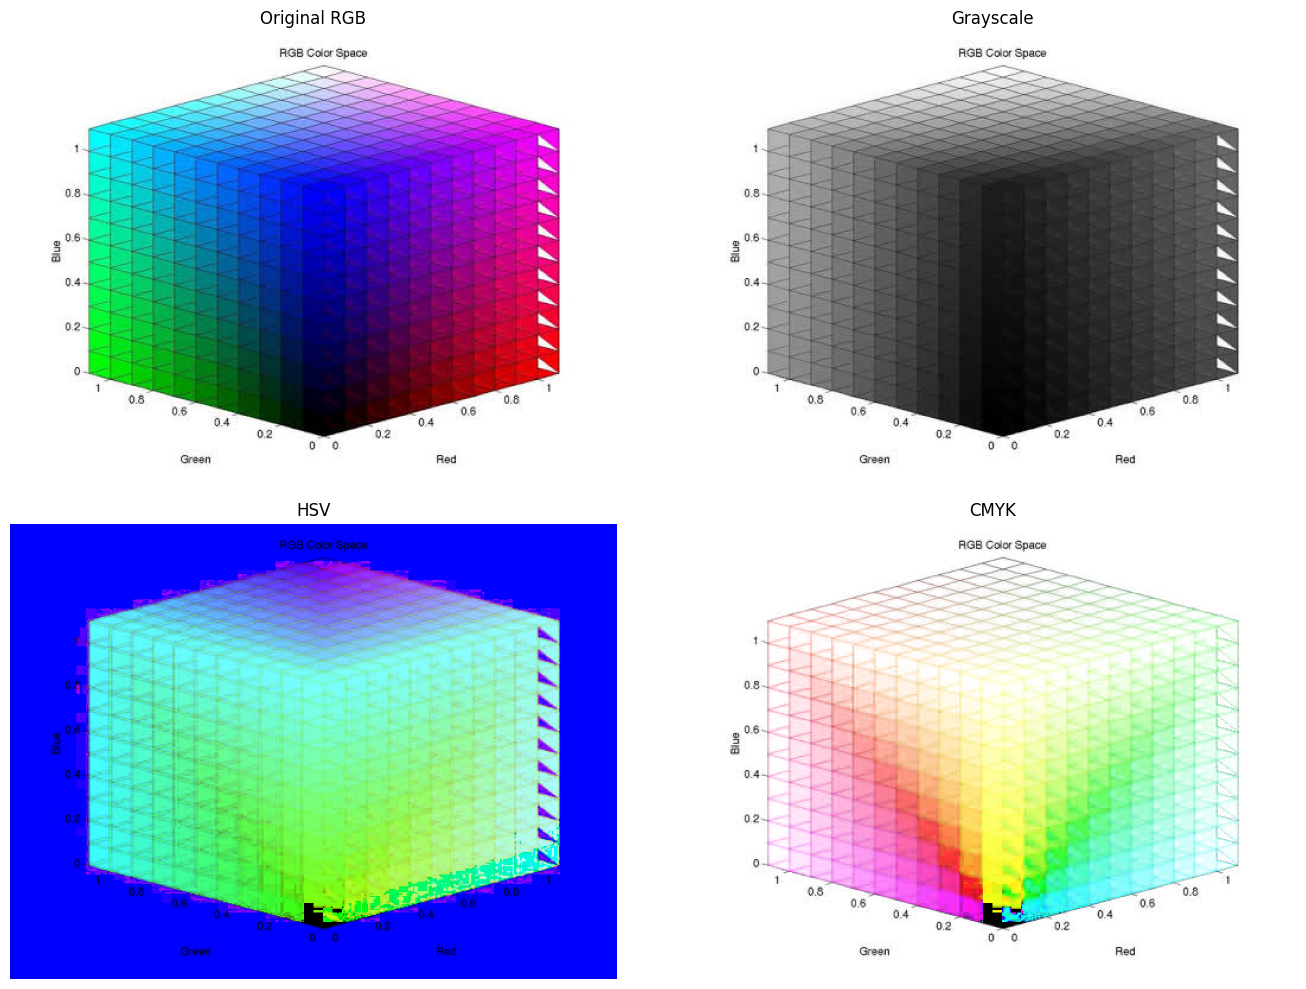

In [ ]:

# Import Libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload Image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Read image
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# RGB to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# RGB to HSV
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

# RGB to CMYK
rgb = img.astype(float) / 255.0
K = 1 - np.max(rgb, axis=2)
C = np.zeros_like(K)
M = np.zeros_like(K)
Y = np.zeros_like(K)

non_black = K < 1
C[non_black] = (1 - rgb[:,:,0][non_black] - K[non_black]) / (1 - K[non_black])
M[non_black] = (1 - rgb[:,:,1][non_black] - K[non_black]) / (1 - K[non_black])
Y[non_black] = (1 - rgb[:,:,2][non_black] - K[non_black]) / (1 - K[non_black])

cmyk = np.stack([C, M, Y, K], axis=2)

# Display Results
titles = ['Original RGB', 'Grayscale', 'HSV', 'CMYK']
images = [img, gray, hsv, cmyk]

plt.figure(figsize=(14, 10))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray' if i == 1 else None)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save output images
cv2.imwrite('grayscale.png', gray)
plt.imsave('hsv.png', hsv)
plt.imsave('cmyk.png', cmyk)
